# Social Buzz | Content Popularity & Business Insights
### Accenture–Forage-inspired end-to-end data analytics case study

**Purpose:** Prepare a defensible portfolio project: business framing → data understanding → cleaning → joins → analytics → visualizations → executive recommendations.

> **DATA PROVENANCE — PLEASE READ:** The data in this package are **deterministically generated synthetic teaching data** using the same three-table design described in public Accenture–Forage Social Buzz walkthroughs. They are **not** a download of the official Forage task files, not verified client results, and not evidence of completing the Accenture simulation. If you get original `Content.csv`, `Reactions.csv`, and `ReactionTypes.csv` from your own enrollment, replace the three files in `data/raw/` and rerun. All actual findings in this notebook refer to the dataset currently loaded.

**Official task sequence:** Project Understanding → Data Cleaning & Modeling → Data Visualization & Storytelling → Present to the Client.

**Client scenario:** Social Buzz needs insights into the **five content categories with the largest aggregate popularity score**, as part of a wider business conversation about data operations and IPO readiness. This notebook implements the **content analytics** workstream; it does *not* pretend to perform a full enterprise data audit or certify IPO readiness.

**Sources:** [Forage](https://www.theforage.com/), [public field explanations](https://github.com/minhaj-313/-Accenture-Data-Analytics-Visualization-Virtual-Internship), [original schema mirrors](https://github.com/iSandeep07/Accenture-Data-Analytics-and-Visualization-).

## 1. Business questions and metric definitions

**Q1:** Which content categories produce the most **aggregate engagement points**?  
**Q2:** Do the top-ranked categories have high **reaction counts** or merely high-scoring reactions?  
**Q3:** Which content formats (photo/video/GIF/audio) perform well?  
**Q4:** What sentiment mix is associated with the reactions?  
**Q5:** How do recorded reactions vary by month?  

In this case, each reaction `Type` maps to a predetermined numeric `Score` in `ReactionTypes.csv`. **Popularity Score of a Category** is

$$S_c = \sum_{i: \mathrm{category}_i=c} s_i.$$

It is a **weighted reaction sum**, not number of unique people, view-through rate, platform-wide reach, revenue, or a machine-learning prediction. Repeated reactions contribute separately unless the business specifies otherwise. Category-level sums can reward categories with more posts: examine **points per content item** as a complementary descriptive metric. Without impressions/exposure and posting time normalization, do not claim one category is intrinsically more attractive to users.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works from extracted zip/project folder. Run notebook from the project root.
ROOT = Path.cwd()
if not (ROOT / 'data' / 'raw').exists() and (ROOT / 'Social_Buzz_Project' / 'data' / 'raw').exists():
    ROOT = ROOT / 'Social_Buzz_Project'
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
FIGURES = ROOT / 'figures'
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print('Project folder:', ROOT.resolve())
print('Raw CSV files:', [p.name for p in RAW.glob('*.csv')])

Project folder: /mnt/data/social_buzz_build
Raw CSV files: ['Reactions.csv', 'ReactionTypes.csv', 'Content.csv']


## 2. Data understanding: three related tables

| Table | Unit of observation | Join key | Core fields | Relationship |
|---|---|---|---|---|
| `Content.csv` | A content post | Content ID | Type = **format**, Category | One post → many reactions |
| `Reactions.csv` | A reaction event | Content ID / reaction Type | Reaction Type, Datetime | Many events → one post |
| `ReactionTypes.csv` | A score mapping | Reaction Type | Sentiment, Score | Many events → one reaction definition |

**Critical interview trap:** `Type` in **Content** means photo/video/GIF/audio; `Type` in **Reactions** means like/love/hate etc. Rename both before joining. Neither `User ID` nor content author names are required to answer the top-category question. Avoid merging by user ID; that would cause an incorrect many-to-many join.

In [2]:
required = ['Content.csv', 'Reactions.csv', 'ReactionTypes.csv']
missing = [name for name in required if not (RAW/name).exists()]
if missing:
    raise FileNotFoundError(f'Missing files: {missing}. Use the complete ZIP or supply your own official Forage CSVs in data/raw.')
content_raw = pd.read_csv(RAW/'Content.csv')
reactions_raw = pd.read_csv(RAW/'Reactions.csv')
reaction_types_raw = pd.read_csv(RAW/'ReactionTypes.csv')
for name, frame in [('Content',content_raw), ('Reactions',reactions_raw), ('Reaction Types',reaction_types_raw)]:
    print(f'{name}: {len(frame):,} rows x {len(frame.columns)} columns | {frame.columns.tolist()}')
    display(frame.head(3))

Content: 1,000 rows x 5 columns | ['Content ID', 'User ID', 'Type', 'Category', 'URL']


,Content ID,User ID,Type,Category,URL
0,SB-00001,U-0346,GIF,science,https://example.org/content/SB-00001
1,SB-00002,U-0552,photo,fitness,https://example.org/content/SB-00002
2,SB-00003,U-0793,video,food,https://example.org/content/SB-00003


Reactions: 25,001 rows x 5 columns | ['Reaction ID', 'Content ID', 'User ID', 'Type', 'Datetime']


,Reaction ID,Content ID,User ID,Type,Datetime
0,RX-0000001,SB-00653,U-3029,indifferent,2025-04-12 16:00:00
1,RX-0000002,SB-00530,U-3625,like,2025-10-01 01:00:00
2,RX-0000003,SB-00085,U-3118,super love,2025-02-26 19:00:00


Reaction Types: 16 rows x 3 columns | ['Type', 'Sentiment', 'Score']


,Type,Sentiment,Score
0,heart,positive,60
1,want,positive,70
2,adore,positive,72


## 3. Data quality profiling — inspect, don't blindly delete

Checks include missing join keys, duplicate event IDs, dates that cannot be parsed, non-numeric scores, and category labels with inconsistent casing/quotes. Missing `User ID` does **not** invalidate a reaction when we are studying category popularity.

The supplied synthetic sample intentionally contains a few broken records for training; a real dataset requires an approved handling policy and an audit trail.

In [3]:
for label,frame in [('Content',content_raw),('Reactions',reactions_raw),('ReactionTypes',reaction_types_raw)]:
    print('\n',label,'— missing values')
    display(frame.isna().sum().rename('null_count').to_frame())
    print('Exact duplicate rows:',frame.duplicated().sum())
    if 'Reaction ID' in frame.columns:
        print('Duplicate reaction event IDs:',frame['Reaction ID'].duplicated().sum())


 Content — missing values


,null_count
Content ID,0
User ID,0
Type,0
Category,1
URL,0


Exact duplicate rows: 0

 Reactions — missing values


,null_count
Reaction ID,0
Content ID,0
User ID,0
Type,1
Datetime,1


Exact duplicate rows: 1
Duplicate reaction event IDs: 1

 ReactionTypes — missing values


,null_count
Type,0
Sentiment,0
Score,0


Exact duplicate rows: 0


## 4. Clean each table separately

- Drop CSV export index columns (e.g. `Unnamed: 0`) only when they are truly non-business identifiers.
- Standardize keys to trimmed strings, normalize case and stray quotes in categories/reaction names.
- Preserve original **content format** and **reaction type** in separate fields.
- Validate reaction-score mapping: **one distinct row per reaction type** (otherwise a join multiplies facts).
- Remove only records that cannot contribute to the specified metric: missing/unmatched content ID, unknown reaction type, invalid date for time analysis, or missing category. Keep a count of losses.
- **Do not** fill missing scores with zero; that silently changes the business definition. Investigate and exclude/report unmatched mappings.

The row grain after merging remains **one reaction event per row**.

In [4]:
def drop_export_indexes(frame):
    return frame.loc[:, ~frame.columns.str.match(r'^Unnamed:')].copy()

def norm_text(series):
    # Pandas nullable strings maintain true missing values.
    return series.astype('string').str.strip()

def norm_category(series):
    return norm_text(series).str.replace('"','',regex=False).str.replace("'",'',regex=False).str.strip().str.lower()

content = drop_export_indexes(content_raw)
content = content.rename(columns={'Content ID':'content_id', 'Type':'content_type', 'Category':'category'})
assert {'content_id','content_type','category'}.issubset(content.columns)
content = content[['content_id','content_type','category']].copy()
content['content_id'] = norm_text(content['content_id'])
content['content_type'] = norm_text(content['content_type']).str.lower()
content['category'] = norm_category(content['category'])
content = content.dropna(subset=['content_id']).drop_duplicates(subset=['content_id'],keep='first')

reaction_types = drop_export_indexes(reaction_types_raw)
reaction_types = reaction_types.rename(columns={'Type':'reaction_type', 'Sentiment':'sentiment', 'Score':'score'})
assert {'reaction_type','sentiment','score'}.issubset(reaction_types.columns)
reaction_types = reaction_types[['reaction_type','sentiment','score']].copy()
reaction_types['reaction_type'] = norm_text(reaction_types['reaction_type']).str.lower()
reaction_types['sentiment'] = norm_text(reaction_types['sentiment']).str.lower()
reaction_types['score'] = pd.to_numeric(reaction_types['score'],errors='coerce')
reaction_types = reaction_types.dropna(subset=['reaction_type','score']).drop_duplicates(subset=['reaction_type'],keep='first')
assert reaction_types['reaction_type'].is_unique

reactions = drop_export_indexes(reactions_raw)
reactions = reactions.rename(columns={'Reaction ID':'reaction_id','Content ID':'content_id','Type':'reaction_type','Datetime':'datetime'})
assert {'content_id','reaction_type','datetime'}.issubset(reactions.columns)
if 'reaction_id' not in reactions.columns:
    # A sequence key represents row identity, not deduplication evidence.
    reactions['reaction_id'] = [f'ROW-{i:08d}' for i in range(len(reactions))]
reactions = reactions[['reaction_id','content_id','reaction_type','datetime']].copy()
reactions['reaction_id']=norm_text(reactions['reaction_id'])
reactions['content_id']=norm_text(reactions['content_id'])
reactions['reaction_type']=norm_text(reactions['reaction_type']).str.lower()
reactions['datetime']=pd.to_datetime(reactions['datetime'],errors='coerce')
# If a stable reaction ID exists, duplicates are duplicates of the event.
if 'Reaction ID' in reactions_raw.columns:
    reactions = reactions.drop_duplicates(subset=['reaction_id'],keep='first')
print('Unique content IDs:',content['content_id'].nunique())
print('Known reaction types:',reaction_types['reaction_type'].nunique())
print('Reaction events after ID deduplication:',len(reactions))

Unique content IDs: 1000
Known reaction types: 16
Reaction events after ID deduplication: 25000


## 5. Data modeling: two many-to-one joins

`Reactions` is the **fact table**; `Content` and `ReactionTypes` are lookup/dimension tables.

```text
Content [content_id]  1  ──────────────── *  Reactions [content_id]
ReactionTypes [reaction_type]  1  ─────── *  Reactions [reaction_type]
```

We first enrich each reaction with its post's category/format, then attach the reaction's weighted score. `validate='many_to_one'` makes pandas raise an error if the lookup contains duplicate keys—this prevents accidentally inflating scores by row multiplication. Preserve unmatched-join counts for QA.

In [5]:
stage1 = reactions.merge(content, on='content_id',how='left',validate='many_to_one',indicator='_content_join')
stage2 = stage1.merge(reaction_types,on='reaction_type',how='left',validate='many_to_one',indicator='_score_join')
qa = {
    'raw_reaction_rows': int(len(reactions_raw)),
    'after_reaction_id_dedup': int(len(reactions)),
    'unmatched_content_ids': int((stage2['_content_join']!='both').sum()),
    'unmatched_reaction_types': int((stage2['_score_join']!='both').sum()),
    'missing_category_after_join': int(stage2['category'].isna().sum()),
    'invalid_datetimes': int(stage2['datetime'].isna().sum())
}
display(pd.Series(qa,name='row_count').to_frame())
required_fields=['content_id','category','content_type','reaction_type','score','datetime']
clean = stage2.dropna(subset=required_fields).copy()
clean['score']=clean['score'].astype(float)
clean['month']=clean['datetime'].dt.to_period('M').astype(str)
clean['date']=clean['datetime'].dt.strftime('%Y-%m-%d')
clean['year']=clean['datetime'].dt.year.astype(int)
clean['month_name']=clean['datetime'].dt.strftime('%b')
clean=clean[['reaction_id','content_id','category','content_type','reaction_type','sentiment','score','datetime','date','month','month_name','year']]
qa['clean_reaction_rows']=int(len(clean))
qa['excluded_after_joins']=int(len(reactions)-len(clean))
assert clean['reaction_id'].is_unique
assert clean[['content_id','category','score','datetime']].notna().all().all()
print('Clean fact-table rows:',len(clean))
display(clean.head())

,row_count
raw_reaction_rows,25001
after_reaction_id_dedup,25000
unmatched_content_ids,1
unmatched_reaction_types,2
missing_category_after_join,11
invalid_datetimes,1


Clean fact-table rows: 24986


,reaction_id,content_id,category,content_type,reaction_type,sentiment,score,datetime,date,month,month_name,year
0,RX-0000001,SB-00653,food,video,indifferent,neutral,20.0,2025-04-12 16:00:00,2025-04-12,2025-04,Apr,2025
1,RX-0000002,SB-00530,tennis,gif,like,positive,50.0,2025-10-01 01:00:00,2025-10-01,2025-10,Oct,2025
2,RX-0000003,SB-00085,animals,photo,super love,positive,75.0,2025-02-26 19:00:00,2025-02-26,2025-02,Feb,2025
4,RX-0000005,SB-00592,fitness,photo,adore,positive,72.0,2025-03-26 15:00:00,2025-03-26,2025-03,Mar,2025
5,RX-0000006,SB-00038,technology,photo,like,positive,50.0,2025-11-12 06:00:00,2025-11-12,2025-11,Nov,2025


## 6. Main deliverable — top five content categories

For category $c$, score is $S_c=\sum_{i\in c} s_i$. The output ranks **total score**, not raw reaction count. We also compute `reaction_events`, `unique_posts`, `score_per_reaction`, and `score_per_post` for context. A high `score_per_post` does not establish causal superiority because impressions, post age and audience size are unavailable.

In [6]:
categories = (clean.groupby('category',as_index=False)
              .agg(popularity_score=('score','sum'),reaction_events=('reaction_id','size'),unique_posts=('content_id','nunique')))
categories['score_per_reaction']=categories['popularity_score']/categories['reaction_events']
categories['score_per_post']=categories['popularity_score']/categories['unique_posts']
categories['share_of_points_pct']=100*categories['popularity_score']/categories['popularity_score'].sum()
categories=categories.sort_values(['popularity_score','category'],ascending=[False,True]).reset_index(drop=True)
top5=categories.head(5).copy()
display(top5.round(2))
print('Top category:',top5.iloc[0]['category'])
print('Top-five combined share of points: %.1f%%' % top5['share_of_points_pct'].sum())

,category,popularity_score,reaction_events,unique_posts,score_per_reaction,score_per_post,share_of_points_pct
0,animals,233200.0,4629,113,50.38,2063.72,18.62
1,science,159316.0,3187,95,49.99,1677.01,12.72
2,technology,141884.0,2816,104,50.38,1364.27,11.33
3,healthy eating,137260.0,2759,93,49.75,1475.91,10.96
4,food,116390.0,2328,87,50.00,1337.82,9.29


Top category: animals
Top-five combined share of points: 62.9%


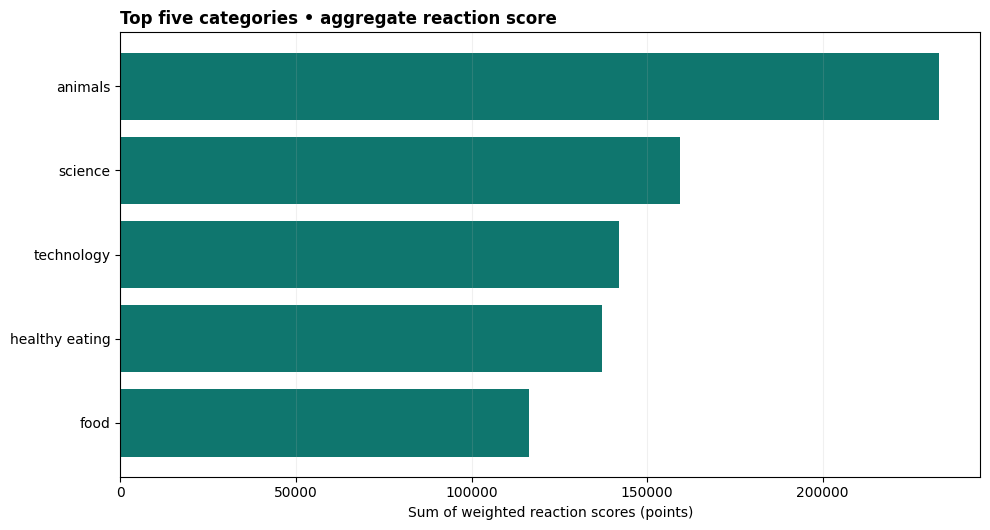

In [7]:
plt.figure(figsize=(10,5.4))
ordered=top5.sort_values('popularity_score')
plt.barh(ordered['category'],ordered['popularity_score'],color='#0F766E')
plt.title('Top five categories • aggregate reaction score',loc='left',fontweight='bold')
plt.xlabel('Sum of weighted reaction scores (points)')
plt.grid(axis='x',alpha=.18)
plt.tight_layout();plt.savefig(FIGURES/'01_top_categories.png',dpi=180,bbox_inches='tight');plt.show()

## 7. Reaction counts vs weighted popularity

A reaction event is counted once. A popularity point equals the **numeric weight** of its reaction type. Two categories can have the same number of events but different total popularity points if their reaction mixes differ.

- Ranking by `reaction_events` answers: "Where were most reaction events recorded?"
- Ranking by `popularity_score` answers: "Where did the largest cumulative weighted score arise?"

Importantly, `reaction_events` is **not** unique viewers or unique users; this schema can contain repeated events per user.

,category,reaction_events,popularity_score,score_per_reaction,unique_posts,score_per_post
0,animals,4629,233200.0,50.38,113,2063.72
1,science,3187,159316.0,49.99,95,1677.01
2,technology,2816,141884.0,50.38,104,1364.27
3,healthy eating,2759,137260.0,49.75,93,1475.91
4,food,2328,116390.0,50.00,87,1337.82
5,fitness,1447,73228.0,50.61,70,1046.11
6,travel,1208,59553.0,49.30,64,930.52
7,culture,1175,59129.0,50.32,54,1094.98
8,cooking,1088,53146.0,48.85,65,817.63
9,education,1008,50454.0,50.05,49,1029.67


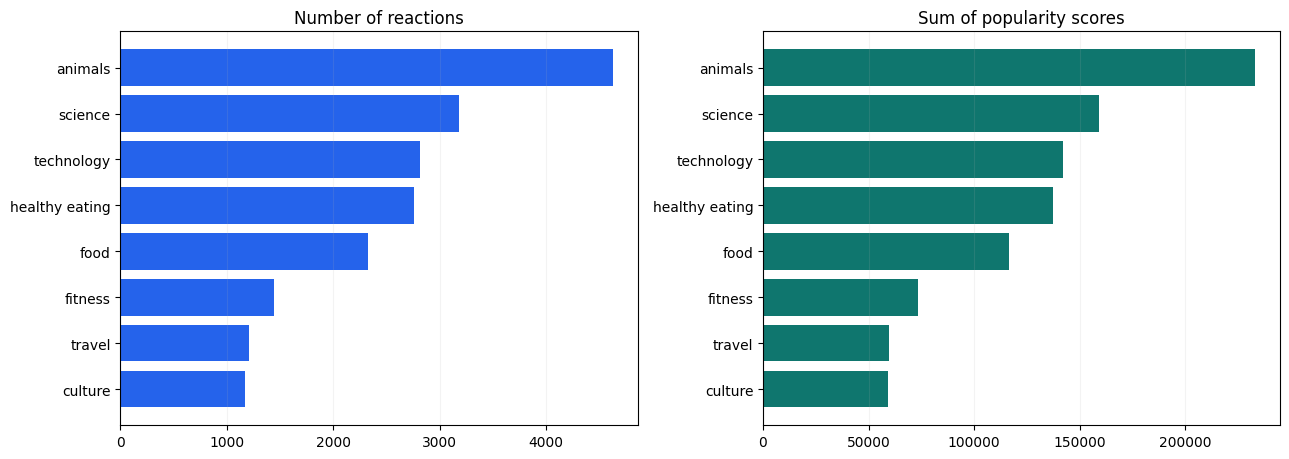

In [8]:
comparison=categories[['category','reaction_events','popularity_score','score_per_reaction','unique_posts','score_per_post']].copy()
display(comparison.head(10).round(2))
fig,axs=plt.subplots(1,2,figsize=(13,4.7))
plot_data=comparison.head(8).iloc[::-1]
axs[0].barh(plot_data['category'],plot_data['reaction_events'],color='#2563EB');axs[0].set_title('Number of reactions')
axs[1].barh(plot_data['category'],plot_data['popularity_score'],color='#0F766E');axs[1].set_title('Sum of popularity scores')
for ax in axs: ax.grid(axis='x',alpha=.15)
plt.tight_layout();plt.savefig(FIGURES/'02_count_vs_score.png',dpi=180,bbox_inches='tight');plt.show()

## 8. How content formats perform

A **content_type** (photo, video, GIF, audio) is the format of the post, not its category. The same category may contain multiple formats. Count events and total points by format. Be careful with "best-performing": a larger total may simply reflect that more of that format was posted.

,content_type,reactions,popularity_score,posts,score_per_post
2,photo,13741,689953.0,512,1347.56
3,video,7472,374332.0,280,1336.90
1,gif,3314,165419.0,172,961.74
0,audio,459,22522.0,35,643.49


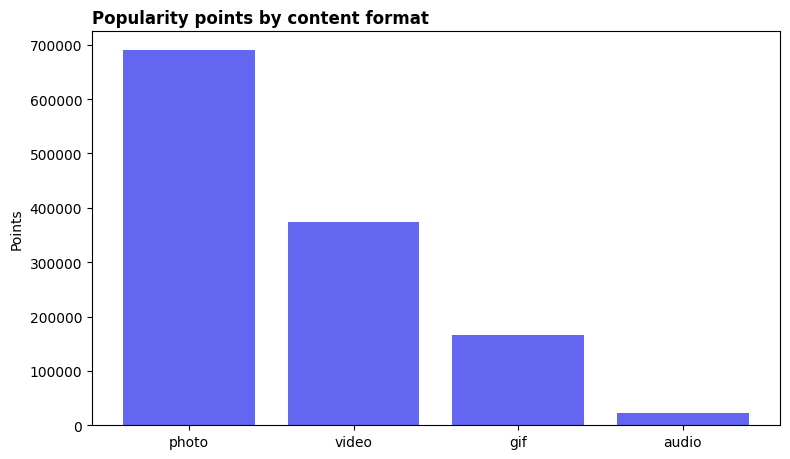

In [9]:
formats=(clean.groupby('content_type',as_index=False)
         .agg(reactions=('reaction_id','size'),popularity_score=('score','sum'),posts=('content_id','nunique'))
         .sort_values('popularity_score',ascending=False))
formats['score_per_post']=formats['popularity_score']/formats['posts']
display(formats.round(2))
plt.figure(figsize=(8,4.7));plt.bar(formats['content_type'],formats['popularity_score'],color='#6366F1')
plt.title('Popularity points by content format',loc='left',fontweight='bold');plt.ylabel('Points');plt.tight_layout()
plt.savefig(FIGURES/'03_formats.png',dpi=180,bbox_inches='tight');plt.show()

## 9. Sentiment analysis — but not NLP

The `ReactionTypes` lookup already labels reaction types as positive / negative / neutral. This is a **rule-based category lookup**, not an ML sentiment classifier. If a user chooses "like", the row inherits its preassigned sentiment; there is no unstructured text sentiment inference.

Count reactions by label to describe composition. Total positive reaction scores reflect the chosen weights, not independently calibrated emotional intensity.

,sentiment,reactions,popularity_score,reaction_pct
0,negative,2445,22312.0,9.79
1,neutral,1463,38335.0,5.86
2,positive,21078,1191579.0,84.36


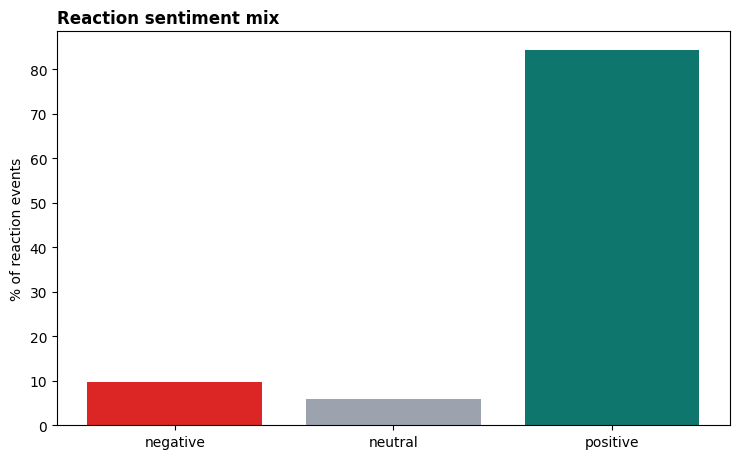

In [10]:
sentiment=(clean.groupby('sentiment',as_index=False).agg(reactions=('reaction_id','size'),popularity_score=('score','sum')))
sentiment['reaction_pct']=100*sentiment['reactions']/sentiment['reactions'].sum()
display(sentiment.round(2))
fig,ax=plt.subplots(figsize=(7.5,4.7))
colors=[{'positive':'#0F766E','negative':'#DC2626','neutral':'#9CA3AF'}.get(x,'#7C3AED') for x in sentiment['sentiment']]
ax.bar(sentiment['sentiment'],sentiment['reaction_pct'],color=colors)
ax.set_ylabel('% of reaction events');ax.set_title('Reaction sentiment mix',loc='left',fontweight='bold')
plt.tight_layout();plt.savefig(FIGURES/'04_sentiment.png',dpi=180,bbox_inches='tight');plt.show()

## 10. Month-by-month activity trends

Use the **reaction timestamp**, not content-creation time (not supplied), to understand when engagements happened. Group by `YYYY-MM` rather than month names alone, so two different years do not get mixed and chronological sorting works correctly. Without an exposure denominator or complete observation windows, trends are descriptive, not evidence of algorithmic causation.

,month,reactions,popularity_score
0,2025-01,1795,90640.0
1,2025-02,1895,94664.0
2,2025-03,2015,102372.0
3,2025-04,1991,98411.0
4,2025-05,2064,104082.0
5,2025-06,2242,112870.0
6,2025-07,1988,98850.0
7,2025-08,1872,93162.0
8,2025-09,2118,105751.0
9,2025-10,2623,130728.0


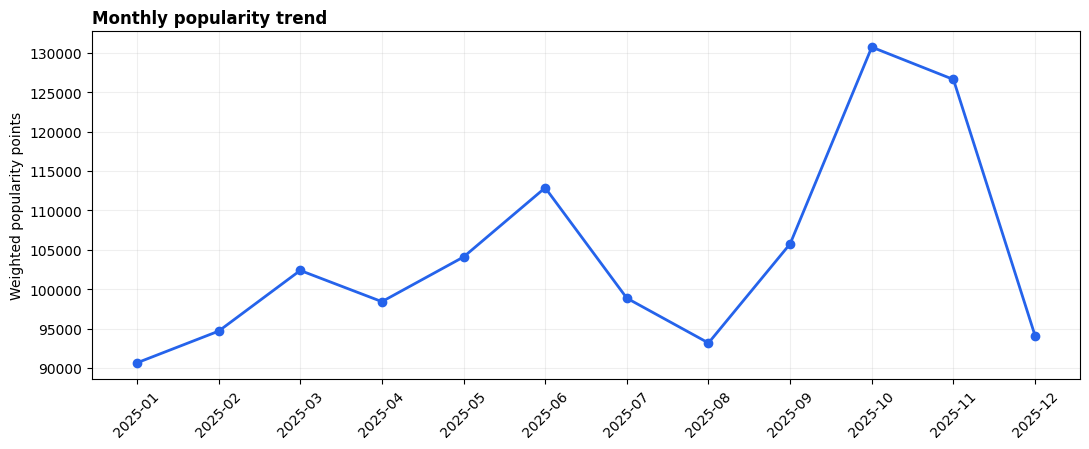

In [11]:
monthly=clean.groupby('month',as_index=False).agg(reactions=('reaction_id','size'),popularity_score=('score','sum'))
monthly=monthly.sort_values('month')
display(monthly)
plt.figure(figsize=(11,4.6));plt.plot(monthly['month'],monthly['popularity_score'],marker='o',color='#2563EB',linewidth=2)
plt.xticks(rotation=45);plt.ylabel('Weighted popularity points');plt.title('Monthly popularity trend',loc='left',fontweight='bold');plt.grid(alpha=.2)
plt.tight_layout();plt.savefig(FIGURES/'05_monthly.png',dpi=180,bbox_inches='tight');plt.show()

## 11. Additional analytical cuts (portfolio extensions)

**Top content posts:** Which individual posts had the highest total scored interactions? **Category × format:** Within which categories did photo/video/GIF gather most observed points? Neither analysis appears as a mandatory machine learning task; these are simple descriptive extensions useful for a more substantial Power BI dashboard.

In [12]:
top_posts=(clean.groupby(['content_id','category','content_type'],as_index=False)
          .agg(reactions=('reaction_id','size'),popularity_score=('score','sum'))
          .sort_values('popularity_score',ascending=False).head(15))
category_format=(clean.groupby(['category','content_type'],as_index=False)
                 .agg(reactions=('reaction_id','size'),popularity_score=('score','sum')))
display(top_posts.head(10));display(category_format.sort_values('popularity_score',ascending=False).head(10))

,content_id,category,content_type,reactions,popularity_score
360,SB-00362,science,video,106,5700.0
943,SB-00945,animals,photo,91,4734.0
308,SB-00310,animals,photo,75,4000.0
823,SB-00825,animals,photo,74,3839.0
244,SB-00246,animals,gif,70,3593.0
117,SB-00119,healthy eating,video,70,3581.0
379,SB-00381,animals,photo,67,3489.0
925,SB-00927,animals,video,71,3470.0
115,SB-00117,animals,photo,69,3435.0
451,SB-00453,science,photo,62,3307.0


,category,content_type,reactions,popularity_score
1,animals,photo,2826,141816.0
36,science,photo,1692,84117.0
28,healthy eating,photo,1413,70134.0
46,technology,photo,1298,66343.0
2,animals,video,1224,61875.0
24,food,photo,1148,56685.0
20,fitness,photo,958,48224.0
47,technology,video,949,47562.0
29,healthy eating,video,907,44956.0
25,food,video,864,43766.0


## 12. Reliability checks, leakage and interpretation

- **Join multiplication check:** every kept reaction should appear once, never once per duplicate lookup key.
- **Score reconciliation:** sum of category points equals the complete fact table's weighted score.
- **Count reconciliation:** category-level event counts equal total clean reaction events.
- **Data lineage:** all exported files derive from the *same* cleaned dataset.
- **Scope guardrails:** sample engagement **is not 500 million users**, true audience exposure, unique reach, retention, causal engagement lift, revenue, or an IPO readiness assessment. This analysis does not train any ML model.
- **Business decision:** prioritizing categories should consider totals **and** normalized performance before scheduling experiments.

In [13]:
assert len(clean) <= len(reactions)
assert clean['reaction_id'].nunique() == len(clean)
assert np.isclose(categories['popularity_score'].sum(),clean['score'].sum())
assert categories['reaction_events'].sum() == len(clean)
assert set(clean['reaction_type']).issubset(set(reaction_types['reaction_type']))
assert set(clean['content_id']).issubset(set(content['content_id']))
assert top5['popularity_score'].is_monotonic_decreasing
print('ALL CHECKS PASSED')
print('Rows in original Reactions CSV:',len(reactions_raw))
print('Rows in validated analytics table:',len(clean))
print('Total measured popularity points:',f"{clean['score'].sum():,.0f}")

ALL CHECKS PASSED
Rows in original Reactions CSV: 25001
Rows in validated analytics table: 24986
Total measured popularity points: 1,252,226


## 13. Export consistent tables for Power BI

**`fact_reactions.csv`** contains one row per cleaned reaction event with category, content format, sentiment, score and time fields; import this single table if you want a beginner-friendly Power BI dashboard. It is already denormalized by the notebook's **validated joins**.

**Why one table?** The raw three-table relationship is important to understand, but a single cleaned event table is easier to use for a report. In a production dimensional model, you might keep separate Content, ReactionTypes, Calendar and Facts tables instead.

The files below are automatically refreshed when you rerun the notebook. If you replace input CSVs with official task data, the dashboard values will update after Power BI data refresh/re-import.

In [14]:
out_fact = clean.rename(columns={
    'reaction_id':'Reaction ID','content_id':'Content ID','category':'Category',
    'content_type':'Content Type','reaction_type':'Reaction Type',
    'sentiment':'Sentiment','score':'Score','datetime':'Datetime',
    'date':'Date','month':'Month','month_name':'Month Name','year':'Year'
})
out_fact.to_csv(PROCESSED/'fact_reactions.csv',index=False)
categories.to_csv(PROCESSED/'category_summary.csv',index=False)
top5.to_csv(PROCESSED/'top5_categories.csv',index=False)
monthly.to_csv(PROCESSED/'monthly_trend.csv',index=False)
sentiment.to_csv(PROCESSED/'sentiment_summary.csv',index=False)
formats.to_csv(PROCESSED/'format_summary.csv',index=False)
top_posts.to_csv(PROCESSED/'top_posts.csv',index=False)
category_format.to_csv(PROCESSED/'category_format.csv',index=False)
qa['total_popularity_points']=float(clean['score'].sum())
qa['top_category']=str(top5.iloc[0]['category'])
qa['top5_score_share_pct']=float(top5['share_of_points_pct'].sum())
(PROCESSED/'quality_report.json').write_text(json.dumps(qa,indent=2),encoding='utf-8')
print('Saved outputs:')
for p in sorted(PROCESSED.iterdir()): print(' •',p.name,p.stat().st_size,'bytes')

Saved outputs:
 • category_format.csv 1577 bytes
 • category_summary.csv 1359 bytes
 • fact_reactions.csv 2590666 bytes
 • format_summary.csv 211 bytes
 • monthly_trend.csv 291 bytes
 • quality_report.json 370 bytes
 • sentiment_summary.csv 171 bytes
 • top5_categories.csv 521 bytes
 • top_posts.csv 564 bytes


## 14. Executive recommendations (suitably qualified)

1. **Prioritize a controlled content experiment** in high-scoring categories rather than declaring causality from rankings. Use engagement-per-impression and comparable posting windows.
2. **Test content formats within each category:** photo/video mix could vary significantly; run A/B tests and compare engagement rate, not only total points.
3. **Improve measurement readiness:** capture impressions, unique exposed users, content age, actual engagement rate and retention so strategic decisions are based on denominators.
4. **Prepare for larger-scale analytics:** establish data contracts, unique event IDs, referential integrity checks, reliable ingestion SLAs and repeatable dashboards; a dashboard is not a complete IPO data audit.

### 30-second interview summary

"I developed an Accenture–Forage-inspired Social Buzz content analytics case. I structured the problem around finding the top five categories by aggregate popularity score, used three related datasets—posts, reactions, and a lookup of reaction scores—and built a validated many-to-one data pipeline. I cleaned missing keys and inconsistent labels, prevented join duplication, ranked categories by weighted scores, and created Power BI-ready datasets and additional visualizations for trends, sentiment and content formats. I then translated the analysis into recommendations for content testing and more reliable engagement measurement. The dataset used for this portfolio build is synthetic, rather than actual Social Buzz client data."